In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import cv2 as cv
import mlflow
from sklearn.model_selection import train_test_split
import tensorflow as tf 
from tensorflow import keras

/home/amrmaarouf/.venvs/mlenv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
I0000 00:00:1792956379.835850   15411 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792956380.759418   15411 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792956382.620143   15411 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical res

In [9]:
mlflow.set_experiment("MNIST_ANN_Experiment")

<Experiment: artifact_location='/mnt/e/Projects/Coding/Python.vscode/Lectures/NN_Lec/mlruns/1', creation_time=1792839062222, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1792839062222, lifecycle_stage='active', name='MNIST_ANN_Experiment', tags={}, trace_location=None, workspace='default'>

In [2]:
(x_train, y_train),(x_test,y_test)  =keras.datasets.mnist.load_data()

print("Original train img: ", x_train.shape)
print("Original test img: ", x_test.shape)

Original train img:  (60000, 28, 28)
Original test img:  (10000, 28, 28)


In [3]:
print("Original train img: ", x_train.shape)


Original train img:  (60000, 28, 28)


In [4]:
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.2, random_state=42)
print("train img: ", x_train.shape)
print("val img: ", x_val.shape)
print("test img: ", x_test.shape)

train img:  (48000, 28, 28)
val img:  (12000, 28, 28)
test img:  (10000, 28, 28)


In [5]:
x_train = x_train / 255.0
x_val = x_val / 255.0
x_test = x_test / 255.0

sample_label is:  3


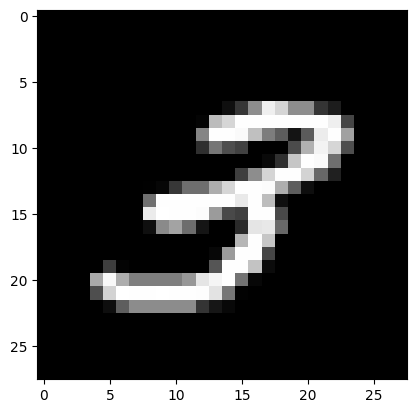

In [14]:
sample_image = x_train[5]
sample_label = y_train[5]
print("sample_label is: ", sample_label)
plt.imshow(sample_image, cmap='gray')

#  Build Our First Neural Network

In [18]:
from mlflow.models import infer_signature

with mlflow.start_run(run_name="MNIST_ANN_BatchSize_Sweep_2"):
    mlflow.log_param("epochs", 5)

    for bs in [16, 32, 64, 128, 256]:
        print(f"Training with batch size: {bs}")

        with mlflow.start_run(run_name=f"bs_{bs}", nested=True):
            model = keras.Sequential([
                keras.Input(shape=(28, 28)),
                keras.layers.Flatten(),
                keras.layers.Dense(128, activation="relu"),
                keras.layers.Dense(10, activation="softmax"),
            ])
            model.compile(
                optimizer="adam",
                loss="sparse_categorical_crossentropy",
                metrics=["accuracy"],
            )
            history = model.fit(
                x_train, y_train,
                batch_size=bs,
                epochs=5,
                validation_data=(x_val, y_val),
                verbose=2,
            )

            mlflow.log_param("batch_size", bs)
            mlflow.log_param("hidden_units", 128)
            mlflow.log_metric("final_train_loss", history.history["loss"][-1])
            mlflow.log_metric("final_train_accuracy", history.history["accuracy"][-1])
            mlflow.log_metric("final_val_loss", history.history["val_loss"][-1])
            mlflow.log_metric("final_val_accuracy", history.history["val_accuracy"][-1])

            signature = infer_signature(x_val[:100], model.predict(x_val[:100], verbose=0))
            mlflow.keras.log_model(model, name="model", signature=signature)

Training with batch size: 16
Epoch 1/5


I0000 00:00:1792842598.349091    6326 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_167886__.12


3000/3000 - 10s - 3ms/step - accuracy: 0.9290 - loss: 0.2464 - val_accuracy: 0.9609 - val_loss: 0.1333
Epoch 2/5
3000/3000 - 8s - 3ms/step - accuracy: 0.9667 - loss: 0.1093 - val_accuracy: 0.9678 - val_loss: 0.1061
Epoch 3/5
3000/3000 - 7s - 2ms/step - accuracy: 0.9777 - loss: 0.0747 - val_accuracy: 0.9706 - val_loss: 0.0996
Epoch 4/5
3000/3000 - 10s - 3ms/step - accuracy: 0.9828 - loss: 0.0557 - val_accuracy: 0.9753 - val_loss: 0.0842
Epoch 5/5
3000/3000 - 8s - 3ms/step - accuracy: 0.9868 - loss: 0.0426 - val_accuracy: 0.9767 - val_loss: 0.0837
Training with batch size: 32
Epoch 1/5


I0000 00:00:1792842652.052200    6328 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_244333__.12


1500/1500 - 5s - 4ms/step - accuracy: 0.9195 - loss: 0.2852 - val_accuracy: 0.9559 - val_loss: 0.1602
Epoch 2/5
1500/1500 - 7s - 5ms/step - accuracy: 0.9637 - loss: 0.1266 - val_accuracy: 0.9685 - val_loss: 0.1074
Epoch 3/5
1500/1500 - 4s - 3ms/step - accuracy: 0.9740 - loss: 0.0866 - val_accuracy: 0.9724 - val_loss: 0.0926
Epoch 4/5
1500/1500 - 4s - 3ms/step - accuracy: 0.9803 - loss: 0.0646 - val_accuracy: 0.9722 - val_loss: 0.0894
Epoch 5/5
1500/1500 - 4s - 3ms/step - accuracy: 0.9849 - loss: 0.0481 - val_accuracy: 0.9767 - val_loss: 0.0760
Training with batch size: 64
Epoch 1/5


I0000 00:00:1792842683.892181    6328 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_283280__.12


750/750 - 4s - 6ms/step - accuracy: 0.9081 - loss: 0.3316 - val_accuracy: 0.9438 - val_loss: 0.1991
Epoch 2/5
750/750 - 2s - 3ms/step - accuracy: 0.9556 - loss: 0.1553 - val_accuracy: 0.9608 - val_loss: 0.1339
Epoch 3/5
750/750 - 2s - 3ms/step - accuracy: 0.9681 - loss: 0.1103 - val_accuracy: 0.9672 - val_loss: 0.1126
Epoch 4/5
750/750 - 2s - 3ms/step - accuracy: 0.9757 - loss: 0.0843 - val_accuracy: 0.9686 - val_loss: 0.1059
Epoch 5/5
750/750 - 5s - 7ms/step - accuracy: 0.9808 - loss: 0.0660 - val_accuracy: 0.9731 - val_loss: 0.0903
Training with batch size: 128
Epoch 1/5


I0000 00:00:1792842707.046021    6326 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_303508__.12


375/375 - 4s - 11ms/step - accuracy: 0.8920 - loss: 0.3980 - val_accuracy: 0.9377 - val_loss: 0.2233
Epoch 2/5
375/375 - 1s - 3ms/step - accuracy: 0.9480 - loss: 0.1850 - val_accuracy: 0.9539 - val_loss: 0.1629
Epoch 3/5
375/375 - 1s - 3ms/step - accuracy: 0.9616 - loss: 0.1363 - val_accuracy: 0.9634 - val_loss: 0.1317
Epoch 4/5
375/375 - 1s - 3ms/step - accuracy: 0.9695 - loss: 0.1060 - val_accuracy: 0.9665 - val_loss: 0.1162
Epoch 5/5
375/375 - 1s - 3ms/step - accuracy: 0.9756 - loss: 0.0860 - val_accuracy: 0.9693 - val_loss: 0.1050
Training with batch size: 256
Epoch 1/5


I0000 00:00:1792842723.035621    6326 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_314393__.12
I0000 00:00:1792842725.114123    6328 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_314393__.12
I0000 00:00:1792842726.390568   13140 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_4', 12 bytes spill stores, 12 bytes spill loads



188/188 - 4s - 24ms/step - accuracy: 0.8654 - loss: 0.4895 - val_accuracy: 0.9285 - val_loss: 0.2597
Epoch 2/5
188/188 - 1s - 5ms/step - accuracy: 0.9379 - loss: 0.2211 - val_accuracy: 0.9457 - val_loss: 0.1931
Epoch 3/5
188/188 - 1s - 4ms/step - accuracy: 0.9530 - loss: 0.1665 - val_accuracy: 0.9563 - val_loss: 0.1587
Epoch 4/5
188/188 - 1s - 4ms/step - accuracy: 0.9628 - loss: 0.1338 - val_accuracy: 0.9619 - val_loss: 0.1371
Epoch 5/5
188/188 - 1s - 4ms/step - accuracy: 0.9692 - loss: 0.1113 - val_accuracy: 0.9664 - val_loss: 0.1213


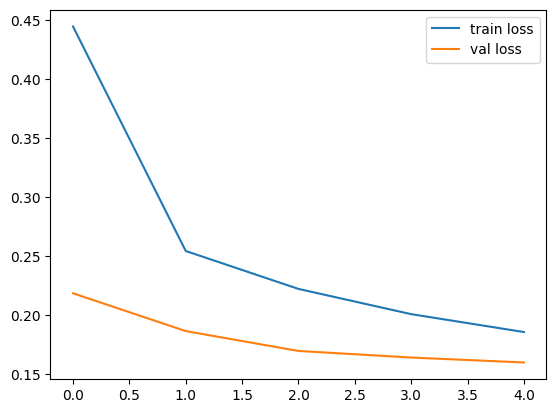

In [19]:
# plot history
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.legend()
plt.show()

In [ ]:
test_loss , test_acc = model.evaluate(x_test,y_test)
print("test_acc: ", test_acc)
print("test_loss: ", test_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9445 - loss: 0.1955
test_acc:  0.9445000290870667
test_loss:  0.19550858438014984


# Predict

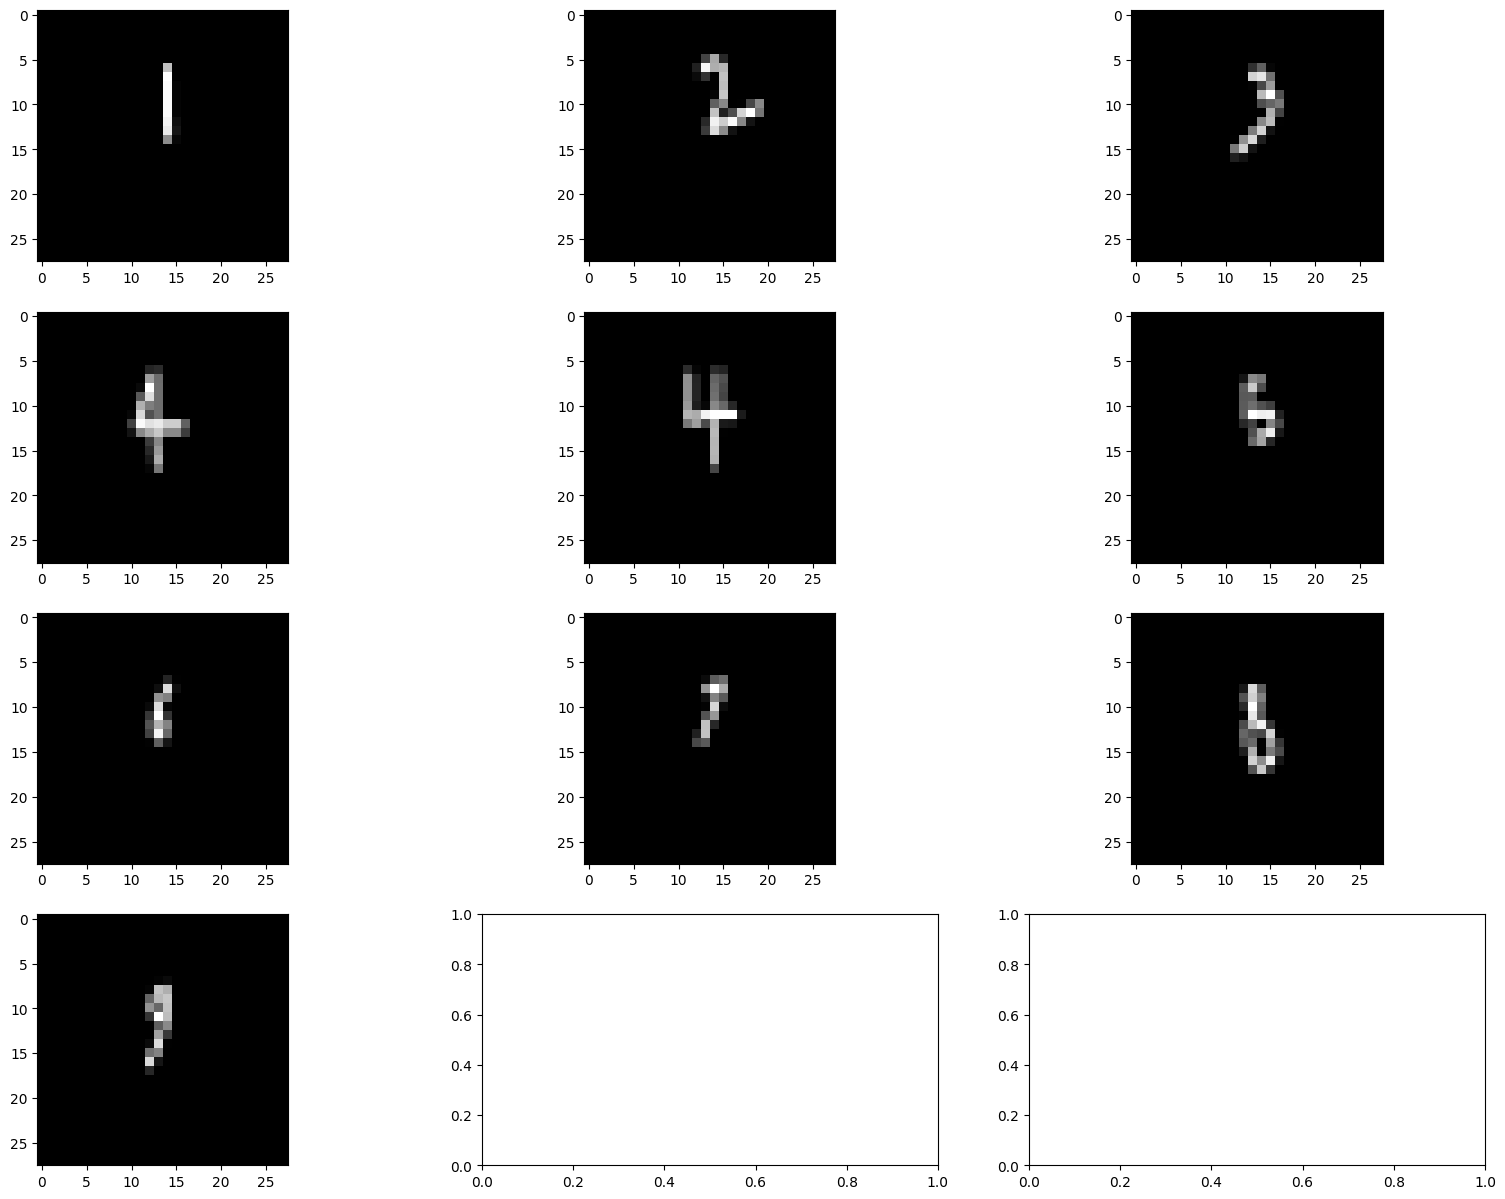

In [27]:
import cv2 as cv
import matplotlib.pyplot as plt

fig, axs = plt.subplots(4, 3, figsize=(20, 15))

for i in [1,2,3]:
    img = cv.imread(f"{i}.png", cv.IMREAD_GRAYSCALE)
    img = cv.resize(img, (28,28), interpolation=cv.INTER_AREA)/255
    img = 1 - img
    axs[0, i-1].imshow(img, cmap='gray')

# 4 part 1
img_4_part1 = cv.imread(r"4 part 1.png", cv.IMREAD_GRAYSCALE)
img_4_part1 = cv.resize(img_4_part1, (28,28), interpolation=cv.INTER_AREA)/255
img_4_part1 = 1 - img_4_part1
axs[1, 0].imshow(img_4_part1, cmap='gray')
    
# 4 part 2
img_4_part2 = cv.imread(r"4 part 2.png", cv.IMREAD_GRAYSCALE)
img_4_part2 = cv.resize(img_4_part2, (28,28), interpolation=cv.INTER_AREA)/255
img_4_part2 = 1 - img_4_part2
axs[1, 1].imshow(img_4_part2, cmap='gray')

for i in [5,6,7,8,9]:
    img = cv.imread(f"{i}.png", cv.IMREAD_GRAYSCALE)
    img = cv.resize(img, (28,28), interpolation=cv.INTER_AREA)/255
    img = 1 - img
    if i < 6:
        axs[1, 2].imshow(img, cmap='gray')
    elif i < 9:
        axs[2, i-6].imshow(img, cmap='gray')
    else:
        axs[3, 0].imshow(img, cmap='gray')

In [28]:
print(model.evaluate(x_test, y_test, verbose=0))

[0.19550858438014984, 0.9445000290870667]


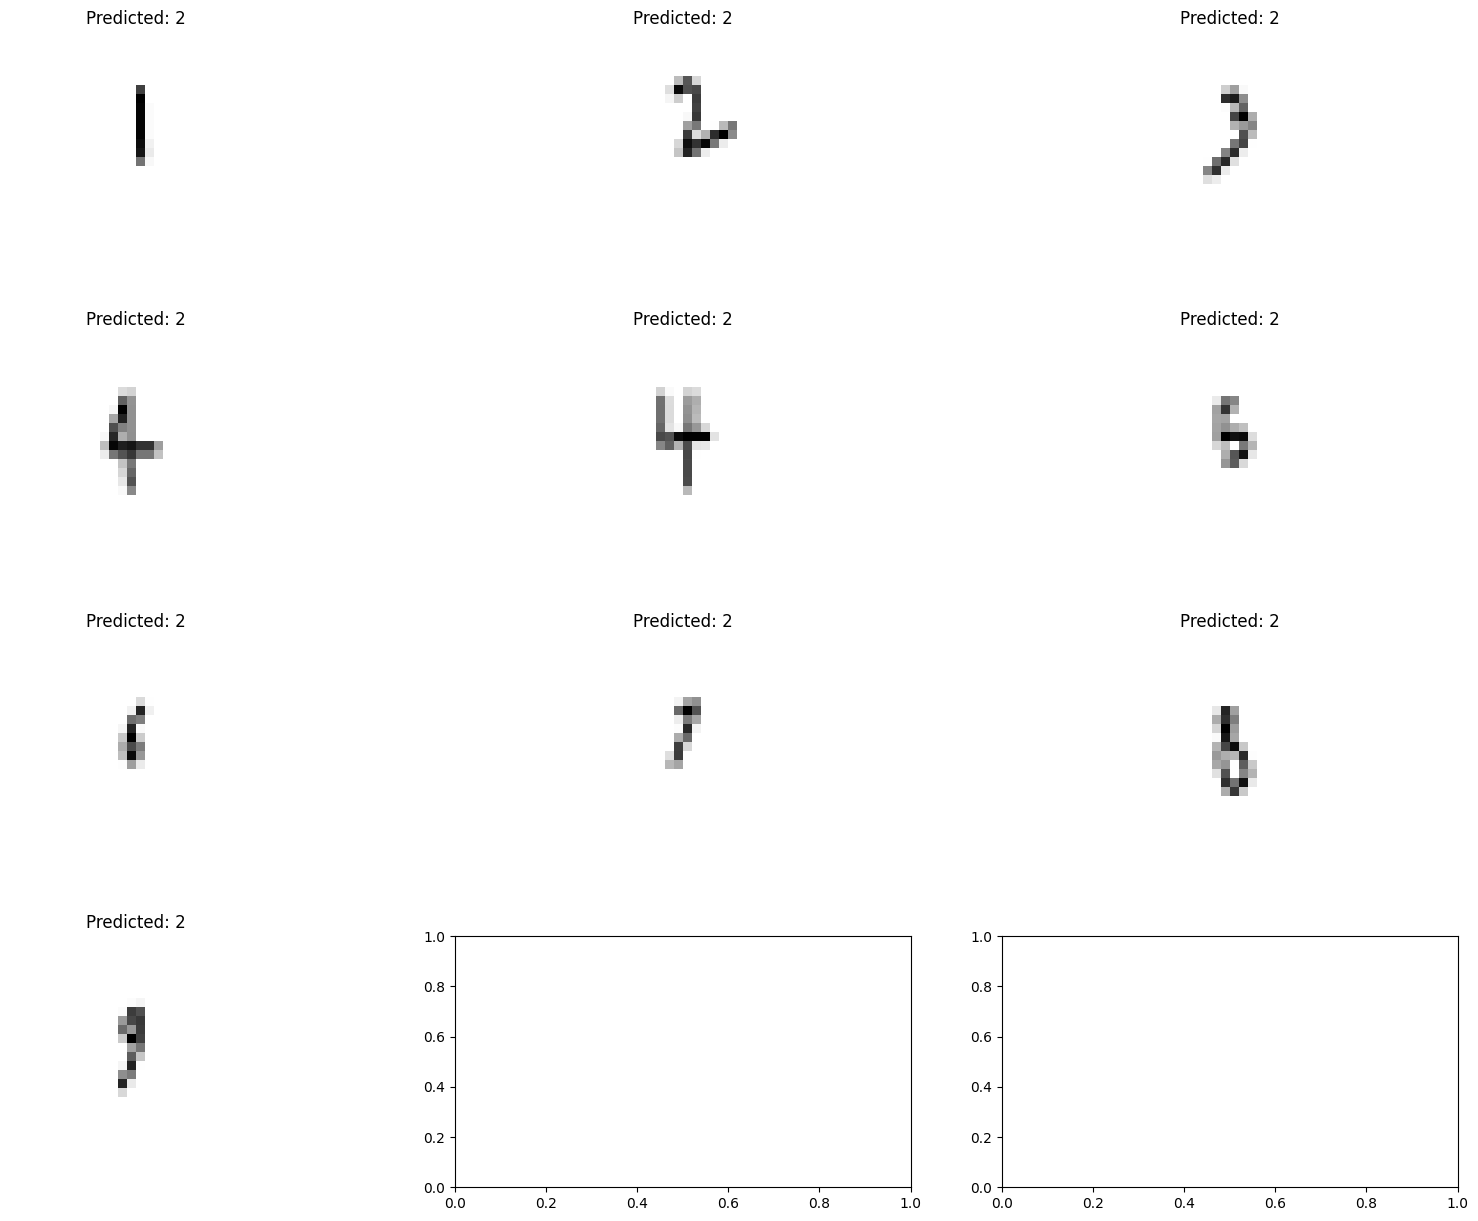

In [29]:
files = ["1.png", "2.png", "3.png", "4 part 1.png", "4 part 2.png", "5.png", "6.png", "7.png", "8.png", "9.png"]
# predict all files images and display the results

fig, axs = plt.subplots(4, 3, figsize=(20, 15))

for i, file in enumerate(files):
    img = cv.imread(file, cv.IMREAD_GRAYSCALE)
    img = cv.resize(img, (28,28), interpolation=cv.INTER_AREA)/255
    prob = model.predict(img.reshape(1,28,28), verbose=0)
    predicted_label = np.argmax(prob)
    axs[i//3, i%3].imshow(img, cmap='gray')
    axs[i//3, i%3].set_title(f"Predicted: {predicted_label}")
    axs[i//3, i%3].axis('off')

plt.show()

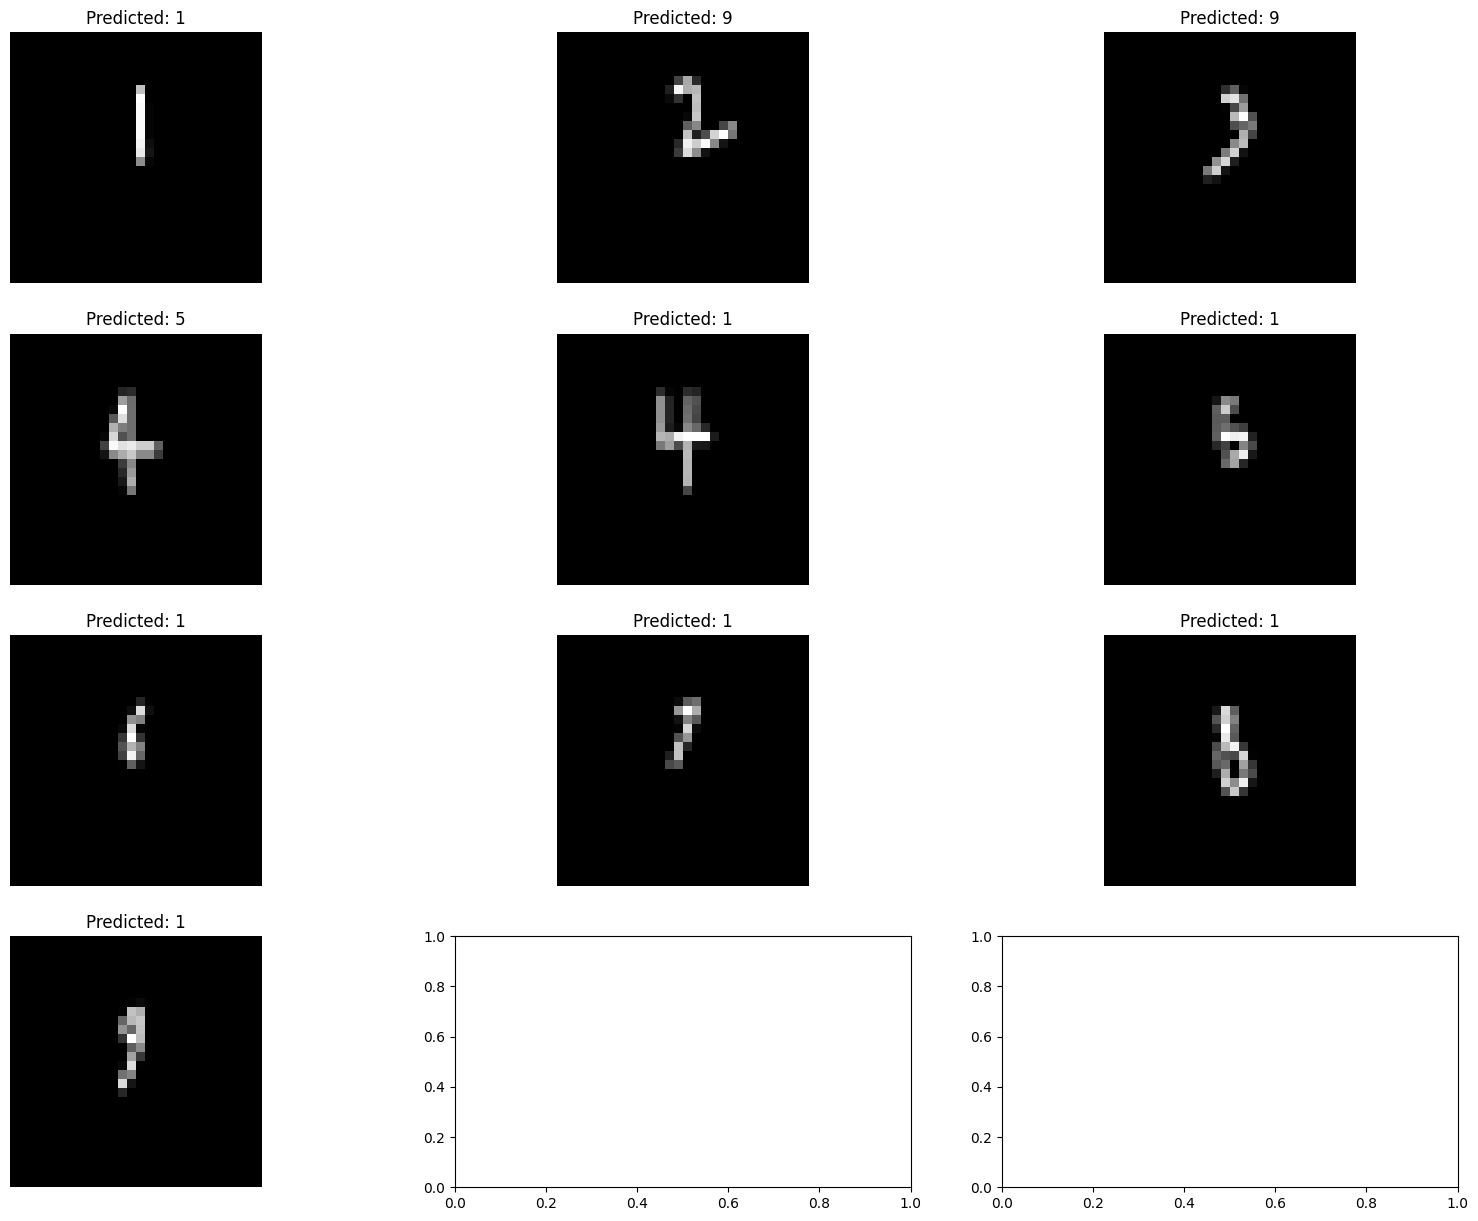

In [30]:
files = ["1.png", "2.png", "3.png", "4 part 1.png", "4 part 2.png", "5.png", "6.png", "7.png", "8.png", "9.png"]
# predict all files images and display the results

fig, axs = plt.subplots(4, 3, figsize=(20, 15))

for i, file in enumerate(files):
    img = cv.imread(file, cv.IMREAD_GRAYSCALE)
    img = cv.resize(img, (28,28), interpolation=cv.INTER_AREA)/255
    img = 1 - img
    prob = model.predict(img.reshape(1,28,28), verbose=0)
    predicted_label = np.argmax(prob)
    axs[i//3, i%3].imshow(img, cmap='gray')
    axs[i//3, i%3].set_title(f"Predicted: {predicted_label}")
    axs[i//3, i%3].axis('off')

plt.show()

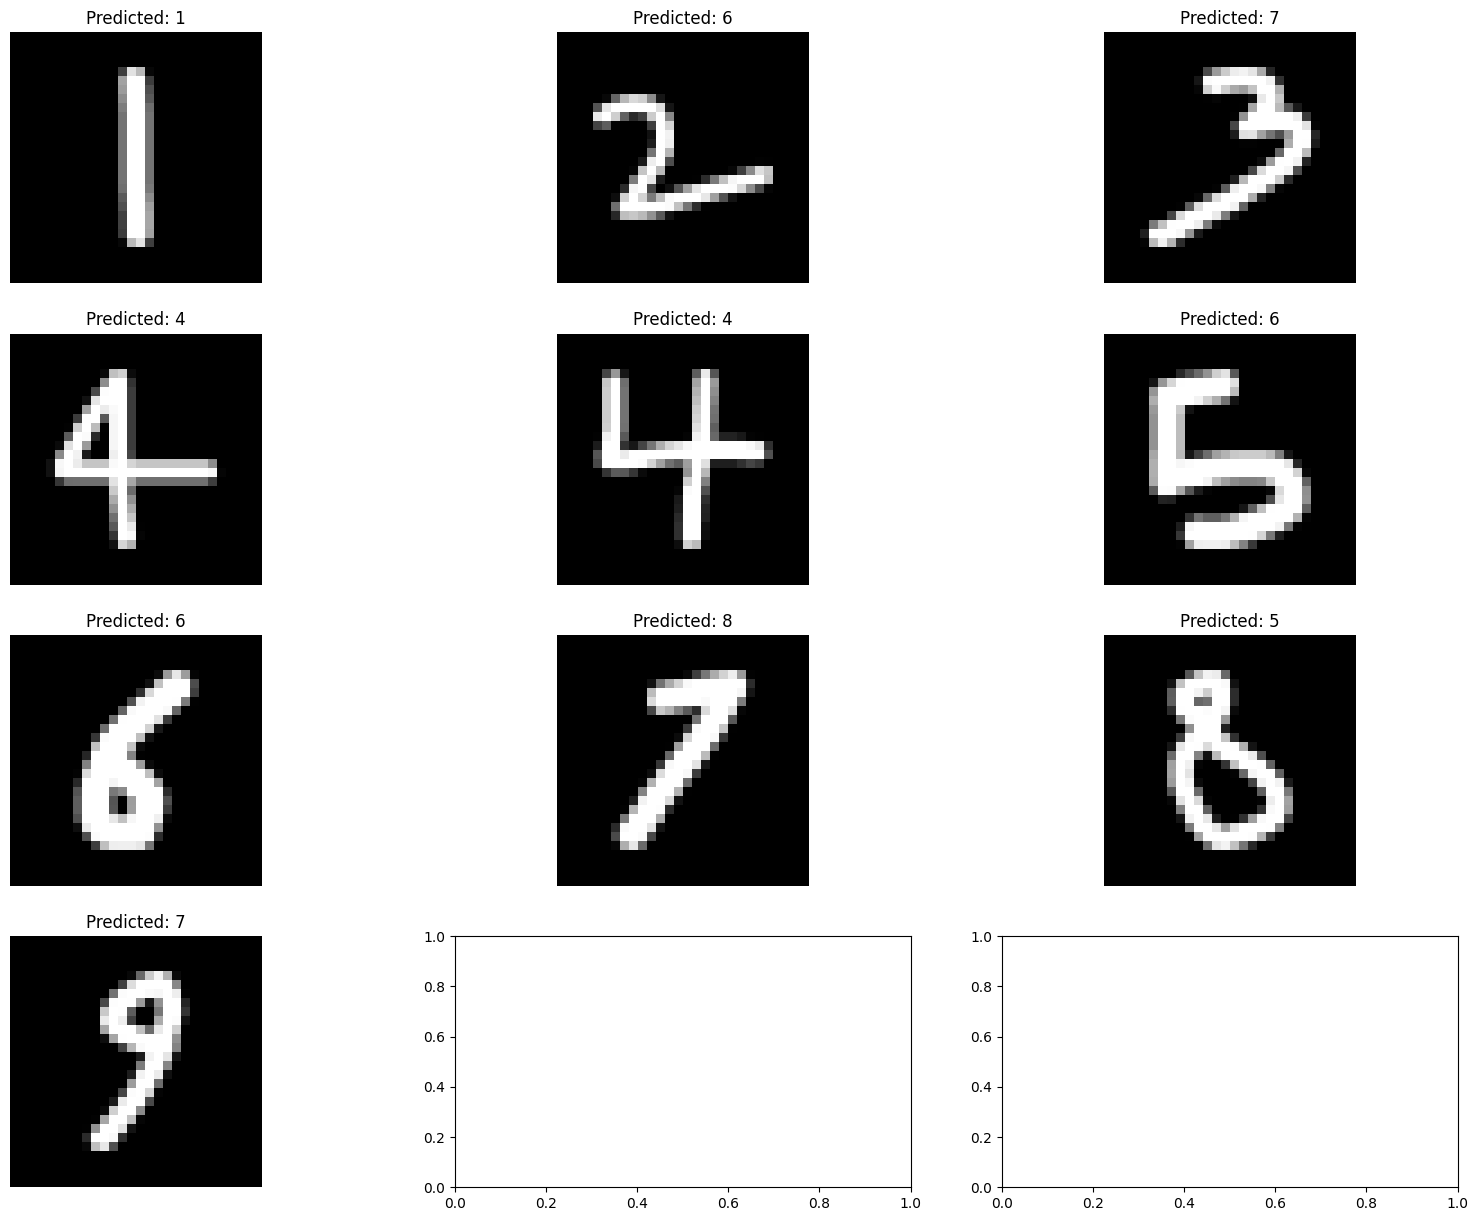

In [31]:
fig, axs = plt.subplots(4, 3, figsize=(20, 15))

for i, file in enumerate(files):
    img = cv.imread(file, cv.IMREAD_GRAYSCALE)
    img = 255 - img                                       # رقم أبيض على أسود
    ys, xs = np.where(img > 50)                           # مكان الحبر
    img = img[ys.min():ys.max()+1, xs.min():xs.max()+1]   # قص حوالين الرقم

    h, w = img.shape
    s = max(h, w)
    pad = np.zeros((s, s), dtype=np.uint8)
    pad[(s-h)//2:(s-h)//2+h, (s-w)//2:(s-w)//2+w] = img

    img = cv.resize(pad, (20, 20), interpolation=cv.INTER_AREA)
    img = np.pad(img, 4) / 255                            # 28x28 بهامش 4

    prob = model.predict(img.reshape(1, 28, 28), verbose=0)
    axs[i//3, i%3].imshow(img, cmap='gray')
    axs[i//3, i%3].set_title(f"Predicted: {np.argmax(prob)}")
    axs[i//3, i%3].axis('off')

plt.show()

NameError: name 'model' is not defined

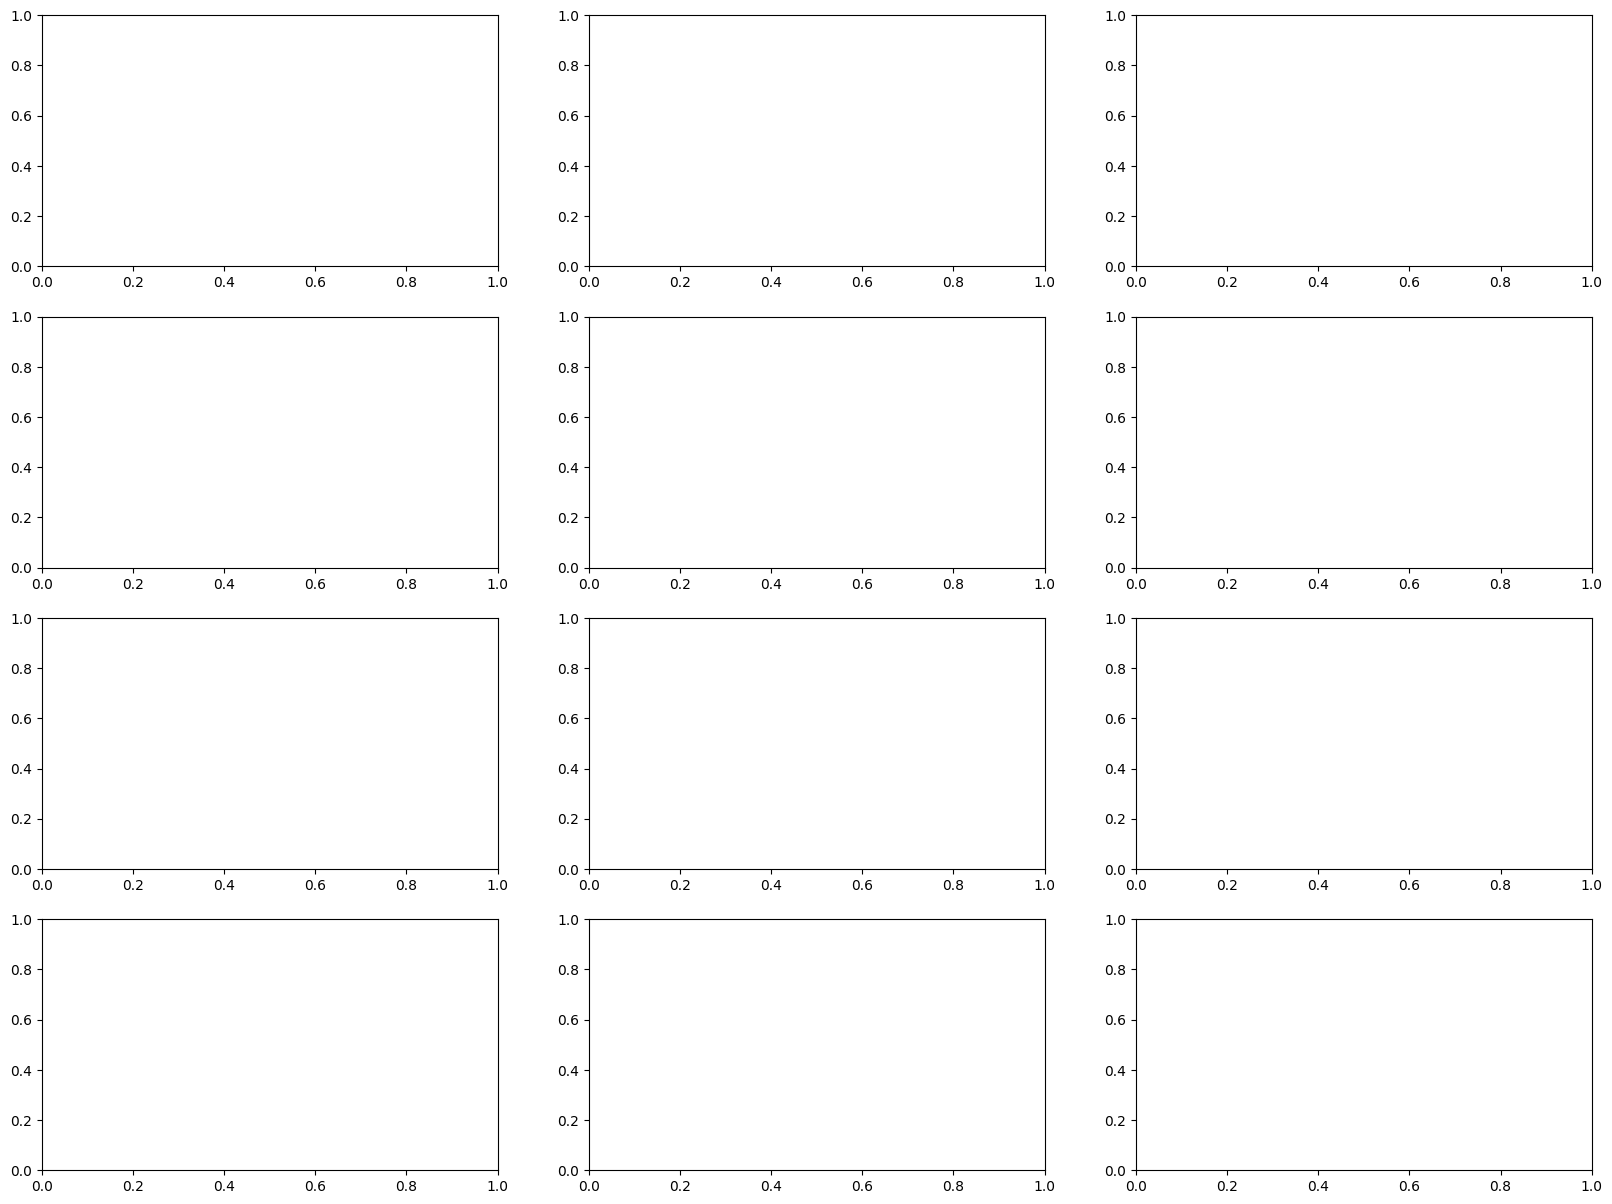

In [12]:
files = ["1.png", "2.png", "3.png", "4 part 1.png", "4 part 2.png", "5.png", "6.png", "7.png", "8.png", "9.png"]

fig, axs = plt.subplots(4, 3, figsize=(20, 15))

for i, file in enumerate(files):
    img = cv.imread(file, cv.IMREAD_GRAYSCALE)
    img = 255 - img                                       # رقم أبيض على أسود
    ys, xs = np.where(img > 50)                           # مكان الحبر
    img = img[ys.min():ys.max()+1, xs.min():xs.max()+1]   # قص حوالين الرقم

    h, w = img.shape
    s = max(h, w)
    pad = np.zeros((s, s), dtype=np.uint8)
    pad[(s-h)//2:(s-h)//2+h, (s-w)//2:(s-w)//2+w] = img
    pad = cv.dilate(pad, np.ones((3, 3), np.uint8), iterations=1)
    img = np.pad(img, 4) / 255
    m = cv.moments(img)
    cx, cy = m["m10"]/m["m00"], m["m01"]/m["m00"]
    M = np.float32([[1, 0, 14 - cx], [0, 1, 14 - cy]])
    img = cv.warpAffine(img, M, (28, 28))

    img = cv.resize(pad, (20, 20), interpolation=cv.INTER_AREA)
    img = np.pad(img, 4) / 255                            # 28x28 بهامش 4

    prob = model.predict(img.reshape(1, 28, 28), verbose=0)
    axs[i//3, i%3].imshow(img, cmap='gray')
    axs[i//3, i%3].set_title(f"Predicted: {np.argmax(prob)}")
    axs[i//3, i%3].axis('off')

plt.show()

2026/10/24 13:51:02 INFO mlflow.tracking.fluent: Experiment with name 'MNIST_ANN_Experiment' does not exist. Creating a new experiment.


<Experiment: artifact_location='/mnt/e/Projects/Coding/Python.vscode/Lectures/NN_Lec/mlruns/1', creation_time=1792839062222, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1792839062222, lifecycle_stage='active', name='MNIST_ANN_Experiment', tags={}, trace_location=None, workspace='default'>

In [ ]:
for i in [32, 64, 128, 256]:
    with mlflow.start_run():

In [20]:
%pip install "akhet[gpu,hub,translate] @ git+https://github.com/AIRI-Institute/akhet#subdirectory=pipeline"

  Cloning https://github.com/AIRI-Institute/akhet to /tmp/pip-install-sbd2ieuf/akhet_2bfc71e5b4204e5892d75cc892d82002
  Running command git clone --filter=blob:none --quiet https://github.com/AIRI-Institute/akhet /tmp/pip-install-sbd2ieuf/akhet_2bfc71e5b4204e5892d75cc892d82002
  Resolved https://github.com/AIRI-Institute/akhet to commit f49249e9ddb7d2545676cb229c759516f49d63f8
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached opencv_python_headless-5.0.0.93-cp37-abi3-manylinux_2_28_x86_64.whl.metadata (19 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 300.5/300.5 MB 3.5 MB/s  0:01:22m0:00:0100:03
Using cached opencv_python_headless-5.0.0.93-cp37-abi3-manylinux_2_28_x86_64.whl (61.2 MB)
  Created wheel for akhet: filename=akhet-0.1.0-py3-none-any.whl size=35432 sha256=e1fc7027b0d3b4780ab0e75d134c261facf18bbe29ef733aa9b9d907095ec03d
  Stored in directory: /tmp/pip-ephem-wheel-cache-zh65yu

In [2]:
from akhet import Akhet, text_blocks, Translator

img_path = "/mnt/e/Projects/Coding/Python.vscode/Datasets/hieroglyphs/real/train/images/img.jpg"

import os
print(os.path.exists(img_path))   # لازم يطلع True قبل ما تكمّل

page = Akhet.from_pretrained()(img_path)
blocks = text_blocks(page)
tr = Translator.from_pretrained()
tr.transliterate(blocks)
tr.translate(blocks, "en")

True


Fetching 7 files: 100%|██████████| 7/7 [00:00<00:00, 501.34it/s]
2026-10-25 20:24:04.426872791 [W:onnxruntime:, transformer_memcpy.cc:111 ApplyImpl] 12 Memcpy nodes are added to the graph main_graph for CUDAExecutionProvider. It might have negative impact on performance (including unable to run CUDA graph). Set session_options.log_severity_level=1 to see the detail logs before this message.
Loading weights: 100%|██████████| 1013/1013 [00:01<00:00, 852.46it/s]


[TextBlock(hieroglyphs='S34 D32 M44 G43 G39 N33 M17 Y5 W9 X1 U30 X1 A51 Z3', transliteration='ꜥnḫ.w sšm.w Zꜣ-H̱nm.w', translation={'en': 'The living one, the herdsman Sa-Chnum.'}, lines=[1], mdc=['S34&&&(D32:M44)*G43-G39&N33-M17*Y5-W9*X1*U30:X1*A51*Z3'], block=0)]

In [3]:
print(page)

Page(width=1024, height=1024, lines=[Line(id=1, box=[269, 1, 717, 1023], score=0.9039800989404633, is_row=False, direction='Right', direction_score=0.7925417945255224, signs=[Sign(box=[504.9662551879883, 63.83476257324219, 697.562385559082, 289.49867248535156], score=0.4745741049207417, code='S34', similarity=0.9987896084785461, candidates=[('S34', 0.9987896084785461), ('U23', 0.2998989224433899), ('S9', 0.28627103567123413), ('R21', 0.2724233567714691), ('Z11', 0.20527082681655884)]), Sign(box=[527.9735107421875, 61.874664306640625, 671.2575912475586, 183.40396118164062], score=0.7603012271041393, code='D32', similarity=0.6619627475738525, candidates=[('D32', 0.6619627475738525), ('L3', 0.4516286253929138), ('D2', 0.4353127181529999), ('D31', 0.4280174970626831), ('AA1', 0.4124777019023895)]), Sign(box=[576.2777938842773, 184.24542236328125, 622.8899154663086, 291.97979736328125], score=0.7920164866099532, code='M44', similarity=0.9497309923171997, candidates=[('M44', 0.94973099231719

In [8]:
poetry = pd.read_parquet(r"/mnt/e/Projects/Coding/Python.vscode/Datasets/Poetry/data/train-00000-of-00002.parquet")
poetry1 = pd.read_parquet(r"/mnt/e/Projects/Coding/Python.vscode/Datasets/Poetry/data/train-00001-of-00002.parquet")

In [11]:
import pandas as pd

base = "/mnt/e/Projects/Coding/Python.vscode/Datasets/Poetry/data"
poetry  = pd.read_parquet(f"{base}/train-00000-of-00002.parquet")
poetry1 = pd.read_parquet(f"{base}/train-00001-of-00002.parquet")

# تأكد إن الأعمدة متطابقة قبل الدمج
assert list(poetry.columns) == list(poetry1.columns)

merged = pd.concat([poetry, poetry1], ignore_index=True)
print(poetry.shape, poetry1.shape, "->", merged.shape)

# تأكد مفيش قصائد مكررة
print("duplicate poems:", merged.duplicated(subset=["poem url"]).sum())
# merged = merged.drop_duplicates(subset=["poem url"]).reset_index(drop=True)  # شيل التعليق لو فيه تكرار

# حفظ النسخة المدمجة
merged.to_parquet(f"{base}/poetry_merged.parquet", index=False)

(127315, 12) (127315, 12) -> (254630, 12)
duplicate poems: 38


In [12]:
poetry = pd.read_parquet(f"{base}/poetry_merged.parquet")

In [10]:
print(poetry.columns.tolist())
print([c for c in poetry.columns if "poet" in c.lower()])

['poem title', 'poem meter', 'poem verses', 'poem theme', 'poem url', 'poet name', 'poet description', 'poet url', 'poet era', 'poet location', 'poem description', 'poem language type']
['poet name', 'poet description', 'poet url', 'poet era', 'poet location']


In [16]:
poet_counts = poetry.groupby("poet name", sort=False).size()

for name, n in poet_counts.items():
    print(f"{name} : {n}")

الامير منجك باشا : 443
الحارث بن عمرو الفزاري : 5
الشريف الرضي : 703
ابن الياسمين : 9
الأشعث بن عابس : 1
العقار بن سليل : 2
عدنان الصائغ : 691
صخر الغي : 12
أبو الهدى الصيادي : 828
ابن النطروني : 3
عبد الولي الشميرى : 55
ابن بشير الإحسائي : 5
أبو بكر بن مجبر : 42
إبراهيم عبد القادر المازني : 127
ماء العينين : 960
هشام الجخ : 7
ابن نفادة : 4
الأبيوردي : 408
مصطفى التل : 107
ابن لبال الشريشي : 46
خلفان بن مصبح : 35
خفاف بن ندبة السلمي : 52
محمد المعولي : 208
نسيب عريضة : 36
عبدالله البردوني : 172
النابغة الغنوي : 1
دريد بن الصمة : 75
محمد ولد ابن ولد أحميدا : 280
أبو العباس الجراوي : 56
جورج جرداق : 8
الحارث بن حلزة : 31
أبو طالب : 76
حفني ناصف : 352
ابن سالم الهمداني : 2
الوليد بن يزيد : 127
ابن الرعلاء : 2
عنترة بن شداد : 144
ابن طفيل : 3
بغثر بن لقيط الأسدي : 8
العباس بن الأحنف : 493
قيس بن ذريح : 115
ابن بشري الصقلي : 3
صردر : 128
ابن حيوس : 136
مدثر بن إبراهيم بن الحجاز : 269
الهدم بن امرئ القيس : 2
ابن دهن الحصي : 4
الإمام الشافعي : 213
عبد القادر الجزائري : 83
الحكم الفزاري : 1
اب

In [17]:
#poet unique names
base = "/mnt/e/Projects/Coding/Python.vscode/Datasets/Poetry"
poetry.to_csv(f"{base}/poetry_full.csv", index=False, encoding="utf-8-sig")